# Drone failure forecasting: survival analysis

Cox and AFT gradient boosting (XGBoost) on right-censored flight hours.

1. Setup
2. Data and time split
3. Training
4. Predicted survival and hazard vs observed
5. Model quality
6. Risk factors (SHAP)
7. Remaining useful life
8. Production model
9. Artifacts for the dashboards

## 1. Setup

In [1]:
%load_ext autoreload
%autoreload 2

import copy
import os
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import shap
from sksurv.nonparametric import kaplan_meier_estimator

from trainer.artifacts import write_artifacts
from trainer.release import (
    PRIORITY_HIGH,
    PRIORITY_MEDIUM,
    GateConfig,
    build_production,
    model_card,
)
from utils import (
    SCALAR_METRICS,
    Model,
    bootstrap_compare,
    calibration_curve,
    evaluate,
    evaluation_times,
    hazard_bandwidth,
    observed_hazard,
    population_hazard,
    remaining_life,
    tune,
)

In [2]:
MODELS_DIR = "./models"
ARTIFACTS_DIR = "./artifacts"

RUL_WINDOW = 100  # look-ahead window of the failure probability, flight hours

In [3]:
FEATURES = [
    "model",
    "environment",
    "is_refurbished",
    "initial_battery_cycles",
    "firmware_major",
    "maintenance_interval_h",
    "operator_experience_yrs",
    "daily_utilization_h",
    "avg_flight_min",
    "avg_payload_kg",
    "payload_ratio",
    "mean_temp_c",
    "avg_humidity_pct",
    "avg_wind_ms",
    "hard_landings_per_100h",
    "mean_vibration_g",
]

CAT_FEATURES = ["model", "environment", "is_refurbished", "firmware_major"]

## 2. Data and time split

Drones are split by commissioning date: the first 70% train, the next 10% validation, the last 20% test. The printed rows are the split shares and the failure share per split.

A censored drone is **in service** if its flight log reaches the data cut-off: `commission_date + duration_h / daily_utilization_h` days is the last day it was observed. Censored drones last seen earlier left the fleet (sold, lost, retired). They stay in the data as censored observations but get no remaining-life forecast.

The split is by cohort, not by calendar time: training drones are followed up to the cut-off, i.e. after the test drones were commissioned. Nothing in these data depends on calendar time, so this is harmless here; with seasonal or fleet-wide effects it would leak the future into training.

In [4]:
df = pd.read_csv("data/drone_survival.csv")

In [5]:
df.head()

,drone_id,model,environment,commission_date,is_refurbished,initial_battery_cycles,firmware_major,maintenance_interval_h,operator_experience_yrs,daily_utilization_h,...,avg_payload_kg,payload_ratio,mean_temp_c,avg_humidity_pct,avg_wind_ms,hard_landings_per_100h,mean_vibration_g,duration_h,event,failure_mode
0,DR-000000,hexa_heavy,urban,2024-08-12,False,22,5,50,3.93,3.42,...,3.886,0.389,-0.1,65.9,4.68,2.60,0.507,224.02,0,censored
1,DR-000001,quad_heavy,coastal,2025-01-06,False,25,4,50,3.99,1.06,...,4.166,0.833,23.7,65.2,5.16,2.72,0.678,380.54,0,censored
2,DR-000002,fixed_wing_vtol,coastal,2024-08-10,False,2,5,50,3.30,1.66,...,2.278,0.759,23.9,73.8,3.70,1.89,0.424,11.57,1,electronics
3,DR-000003,hexa_heavy,urban,2024-11-05,False,5,3,25,3.34,2.48,...,7.129,0.713,11.2,57.8,3.78,1.00,0.440,1044.08,0,censored
4,DR-000004,quad_light,urban,2025-04-25,False,8,4,200,2.11,1.63,...,0.335,0.335,19.2,54.7,6.20,1.63,0.367,63.67,1,crash


In [6]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 21 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   drone_id                 5000 non-null   str    
 1   model                    5000 non-null   str    
 2   environment              5000 non-null   str    
 3   commission_date          5000 non-null   str    
 4   is_refurbished           5000 non-null   bool   
 5   initial_battery_cycles   5000 non-null   int64  
 6   firmware_major           5000 non-null   int64  
 7   maintenance_interval_h   5000 non-null   int64  
 8   operator_experience_yrs  5000 non-null   float64
 9   daily_utilization_h      5000 non-null   float64
 10  avg_flight_min           5000 non-null   float64
 11  avg_payload_kg           5000 non-null   float64
 12  payload_ratio            5000 non-null   float64
 13  mean_temp_c              5000 non-null   float64
 14  avg_humidity_pct         5000 non-n

In [7]:
df["commission_date"] = pd.to_datetime(df["commission_date"])

# Last day each drone was observed. For a drone still flying it is the data cut-off;
# a censored drone last seen earlier has left the fleet.
last_seen = df["commission_date"] + pd.to_timedelta(
    df["duration_h"] / df["daily_utilization_h"], unit="D"
)
cutoff = last_seen.max()
df["in_service"] = (df["event"] == 0) & (last_seen > cutoff - pd.Timedelta(days=1))

t_val, t_test = df["commission_date"].quantile([0.70, 0.80])

train = df[df["commission_date"] < t_val]
val = df[(df["commission_date"] >= t_val) & (df["commission_date"] < t_test)]
test = df[df["commission_date"] >= t_test]

print(len(train) / len(df), len(val) / len(df), len(test) / len(df))
print(train["event"].mean(), val["event"].mean(), test["event"].mean())
print(
    f"Data cut-off {cutoff.date()}: {(df['event'] == 0).sum()} censored drones, "
    f"{df['in_service'].sum()} of them in service"
)

0.6998 0.1 0.2002
0.6630465847384968 0.546 0.44755244755244755
Data cut-off 2025-12-31: 1959 censored drones, 1586 of them in service


## 3. Training

Hyper-parameters: Optuna on the validation Integrated Brier score; early stopping on validation.

The models are then recalibrated for unobserved heterogeneity between drones (`Model.calibrate`). Drones with the same features still differ in durability; the weaker ones fail first, so the survivors of a high-risk group are sturdier than their features suggest. The correction replaces the cumulative hazard $H$ with $\log(1 + v \cdot k \cdot H) / v$, where $v$ is the variance of the hidden durability (gamma frailty); $v = 0$, $k = 1$ changes nothing. It is fitted on out-of-fold predictions for train, so validation and test stay untouched. A model keeps the correction only if its fitted variance is above 0: with $v = 0$ the link is a plain rescaling of the hazard, which this step is not meant to make. Section 7.2 shows what the correction changes.

The fitted models are saved and reloaded to check the round trip.

These are the **evaluation** models: sections 4-7 measure them on the test split. The models that score new drones are refitted on train + validation in section 8.

In [8]:
N_TRIALS = 60

best_cox = tune("cox", train, val, N_TRIALS, FEATURES, CAT_FEATURES)
best_aft = tune("aft", train, val, N_TRIALS, FEATURES, CAT_FEATURES)

[I 2026-11-19 11:43:03,239] A new study created in memory with name: no-name-f5b68f1f-7ca9-4892-9051-f5d809d04790


[I 2026-11-19 11:43:03,427] Trial 0 finished with value: 0.16444699142841954 and parameters: {'max_depth': 3, 'eta': 0.13732181501427546, 'min_child_weight': 12.057126287443763, 'subsample': 0.8795975452591109, 'colsample_bytree': 0.7468055921327309, 'reg_lambda': 0.22853255256339203}. Best is trial 0 with value: 0.16444699142841954.


[I 2026-11-19 11:43:03,865] Trial 1 finished with value: 0.1633328090548445 and parameters: {'max_depth': 2, 'eta': 0.1180201220859558, 'min_child_weight': 7.725378389307352, 'subsample': 0.9124217733388136, 'colsample_bytree': 0.7061753482887407, 'reg_lambda': 17.052641538983092}. Best is trial 1 with value: 0.1633328090548445.


[I 2026-11-19 11:43:04,262] Trial 2 finished with value: 0.16432768882386797 and parameters: {'max_depth': 5, 'eta': 0.03657395726919529, 'min_child_weight': 1.8559980846490576, 'subsample': 0.7550213529560301, 'colsample_bytree': 0.7912726728878613, 'reg_lambda': 1.6124278458562613}. Best is trial 1 with value: 0.1633328090548445.


[I 2026-11-19 11:43:04,789] Trial 3 finished with value: 0.16329558643611208 and parameters: {'max_depth': 3, 'eta': 0.04212698016841976, 'min_child_weight': 8.012737503998538, 'subsample': 0.7418481581956126, 'colsample_bytree': 0.7876433945605654, 'reg_lambda': 0.6966418981413739}. Best is trial 3 with value: 0.16329558643611208.


[I 2026-11-19 11:43:05,139] Trial 4 finished with value: 0.16512286745436264 and parameters: {'max_depth': 3, 'eta': 0.1020764751473924, 'min_child_weight': 1.9721610970573997, 'subsample': 0.8542703315240835, 'colsample_bytree': 0.8777243706586128, 'reg_lambda': 0.12790390175145838}. Best is trial 3 with value: 0.16329558643611208.


... (112 outputs left out)

[I 2026-11-19 11:43:58,873] Trial 56 finished with value: 0.1623467350235074 and parameters: {'max_depth': 5, 'eta': 0.03697940589114285, 'min_child_weight': 19.791962734047303, 'subsample': 0.8678440763767608, 'colsample_bytree': 0.8064509258568275, 'reg_lambda': 7.140424141032988, 'aft_loss_distribution': 'logistic', 'aft_loss_distribution_scale': 0.5671323716236303}. Best is trial 32 with value: 0.1615117171595797.


[I 2026-11-19 11:43:59,428] Trial 57 finished with value: 0.16160341955351307 and parameters: {'max_depth': 5, 'eta': 0.034541461669991336, 'min_child_weight': 15.303191799268411, 'subsample': 0.8656211605118997, 'colsample_bytree': 0.7847960825025522, 'reg_lambda': 6.671435698123979, 'aft_loss_distribution': 'logistic', 'aft_loss_distribution_scale': 0.6168391626413435}. Best is trial 32 with value: 0.1615117171595797.


[I 2026-11-19 11:44:00,288] Trial 58 finished with value: 0.1633964157087989 and parameters: {'max_depth': 5, 'eta': 0.03976395921789542, 'min_child_weight': 22.733395887107648, 'subsample': 0.8780559451430284, 'colsample_bytree': 0.8080175695110313, 'reg_lambda': 15.997148118518941, 'aft_loss_distribution': 'logistic', 'aft_loss_distribution_scale': 0.540725138656012}. Best is trial 32 with value: 0.1615117171595797.


[I 2026-11-19 11:44:01,144] Trial 59 finished with value: 0.16380220820351737 and parameters: {'max_depth': 5, 'eta': 0.029485476844063115, 'min_child_weight': 13.804534221775647, 'subsample': 0.9743300482485132, 'colsample_bytree': 0.7955956442671656, 'reg_lambda': 1.3650906825268554, 'aft_loss_distribution': 'logistic', 'aft_loss_distribution_scale': 0.6407415106158154}. Best is trial 32 with value: 0.1615117171595797.


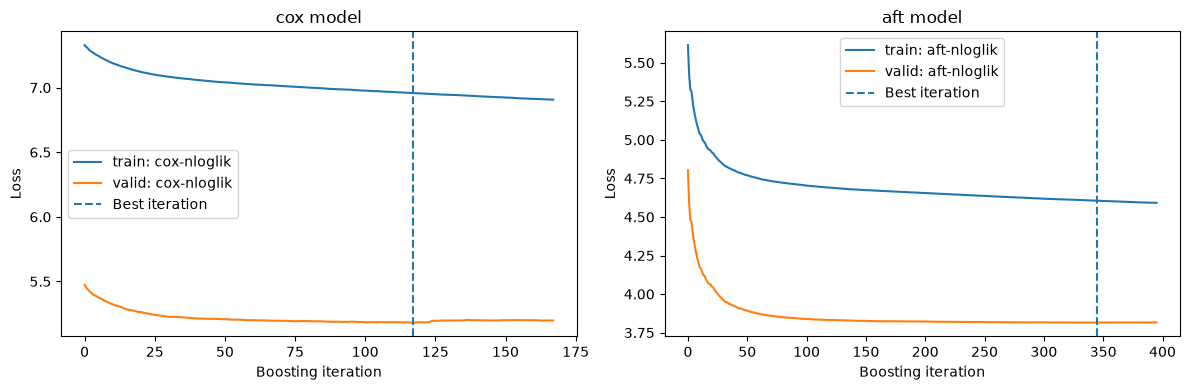

In [9]:
models = {"cox": best_cox, "aft": best_aft}

fig, axes = plt.subplots(1, len(models), figsize=(12, 4))

for ax, (name, model) in zip(axes, models.items()):
    for split, history in model.history.items():
        for metric, values in history.items():
            ax.plot(values, label=f"{split}: {metric}")

    ax.axvline(model.booster.best_iteration, linestyle="--", label="Best iteration")
    ax.set_title(f"{name} model")
    ax.set_xlabel("Boosting iteration")
    ax.set_ylabel("Loss")
    ax.legend()

plt.tight_layout()
plt.show()

In [10]:
# Recalibrate for unobserved heterogeneity between drones; fitted on out-of-fold
# predictions for train (five refits per model with the tuned parameters)
fitted = {name: model.calibrate(train, val).calibration for name, model in models.items()}

# A variance of 0 means no heterogeneity was found: that model stays as trained
for model in models.values():
    if model.calibration["frailty_variance"] < 1e-8:
        model.calibration = None

pd.DataFrame(fitted).T.assign(
    applied=[model.calibration is not None for model in models.values()]
).round(3)

,frailty_variance,scale,applied
cox,0.289,1.052,True
aft,0.000,1.033,False


In [11]:
os.makedirs(MODELS_DIR, exist_ok=True)

best_cox.save("./models/best_cox.json")
best_aft.save("./models/best_aft.json")

best_cox = Model.load("./models/best_cox.json")
best_aft = Model.load("./models/best_aft.json")

## 4. Predicted survival and hazard vs observed (test)

### 4.1 Survival S(t)

Left: mean predicted curve vs Kaplan-Meier. Right: five random drones.

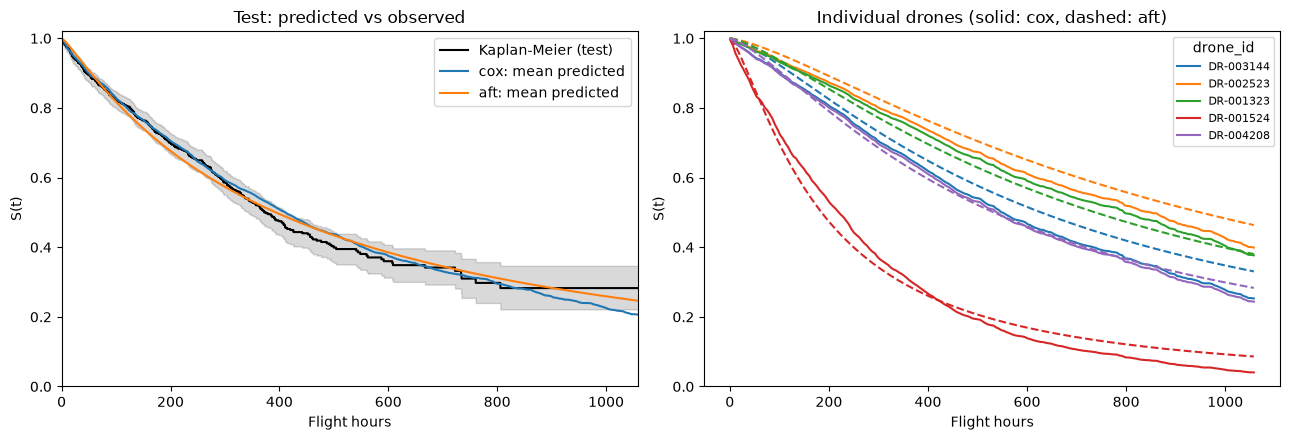

In [12]:
models = {"cox": best_cox, "aft": best_aft}

grid = np.linspace(1, np.quantile(train["duration_h"], 0.95), 200)
curves = {name: model.survival(test, grid) for name, model in models.items()}

km_time, km_surv, km_ci = kaplan_meier_estimator(
    test["event"].astype(bool), test["duration_h"], conf_type="log-log"
)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

ax = axes[0]
ax.step(km_time, km_surv, where="post", color="black", label="Kaplan-Meier (test)")
ax.fill_between(km_time, km_ci[0], km_ci[1], step="post", color="black", alpha=0.15)
for name, S in curves.items():
    ax.plot(grid, S.mean(axis=0), label=f"{name}: mean predicted")
ax.set(
    title="Test: predicted vs observed",
    xlabel="Flight hours",
    ylabel="S(t)",
    xlim=(0, grid[-1]),
    ylim=(0, 1.02),
)
ax.legend()

ax = axes[1]
idx = np.random.default_rng(0).choice(len(test), size=5, replace=False)
for k, i in enumerate(idx):
    ax.plot(grid, curves["cox"][i], color=f"C{k}", label=test["drone_id"].iloc[i])
    ax.plot(grid, curves["aft"][i], color=f"C{k}", linestyle="--")
ax.set(
    title="Individual drones (solid: cox, dashed: aft)",
    xlabel="Flight hours",
    ylabel="S(t)",
    ylim=(0, 1.02),
)
ax.legend(title="drone_id", fontsize=8)

plt.tight_layout()
plt.show()

### 4.2 Hazard h(t)

Left: predicted fleet hazard vs the kernel-smoothed Nelson-Aalen estimate. Right: the same five drones.

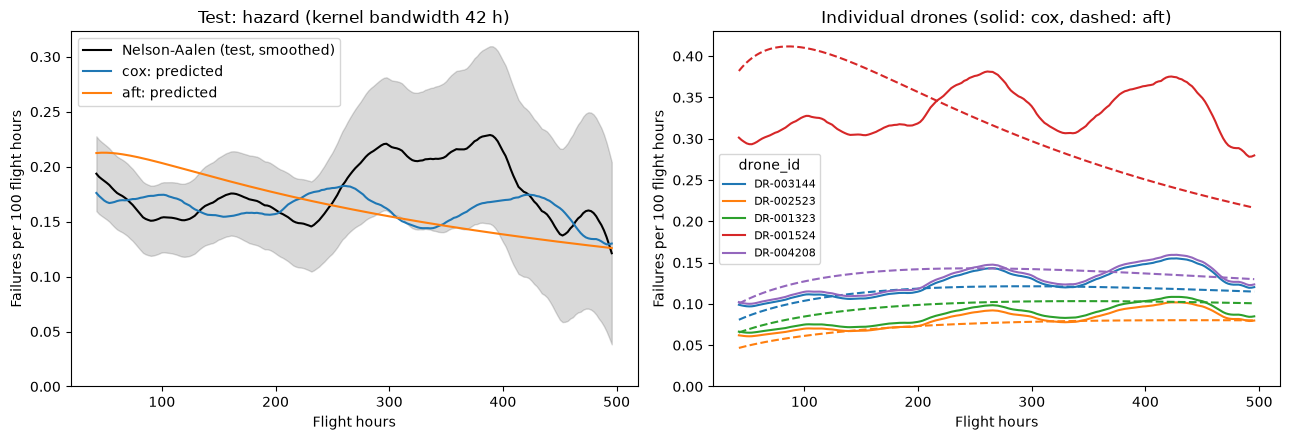

In [13]:
# Hazard h(t): failure rate among drones still flying at t, per 100 flight hours.
# Observed: kernel-smoothed Nelson-Aalen on test. Predicted: survival-weighted mean of
# the individual hazards over the same drones. The kernel loses mass near 0, so the
# grid starts one bandwidth in.
bandwidth = hazard_bandwidth(test["duration_h"], test["event"])
hz_grid = np.linspace(bandwidth, np.quantile(test["duration_h"], 0.9), 200)
hz_obs, hz_low, hz_high = observed_hazard(
    test["duration_h"], test["event"], hz_grid, bandwidth
)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

ax = axes[0]
ax.plot(hz_grid, 100 * hz_obs, color="black", label="Nelson-Aalen (test, smoothed)")
ax.fill_between(hz_grid, 100 * hz_low, 100 * hz_high, color="black", alpha=0.15)
for name, model in models.items():
    pop = population_hazard(model, test, hz_grid, bandwidth)
    ax.plot(hz_grid, 100 * pop, label=f"{name}: predicted")
ax.set(
    title=f"Test: hazard (kernel bandwidth {bandwidth:.0f} h)",
    xlabel="Flight hours",
    ylabel="Failures per 100 flight hours",
    ylim=(0, None),
)
ax.legend()

ax = axes[1]
sample = test.iloc[idx]
sample_hazard = {name: model.hazard(sample, hz_grid, bandwidth) for name, model in models.items()}
for k, drone_id in enumerate(sample["drone_id"]):
    ax.plot(hz_grid, 100 * sample_hazard["cox"][k], color=f"C{k}", label=drone_id)
    ax.plot(hz_grid, 100 * sample_hazard["aft"][k], color=f"C{k}", linestyle="--")
ax.set(
    title="Individual drones (solid: cox, dashed: aft)",
    xlabel="Flight hours",
    ylabel="Failures per 100 flight hours",
    ylim=(0, None),
)
ax.legend(title="drone_id", fontsize=8)

plt.tight_layout()
plt.show()

## 5. Model quality

### 5.1 Metrics and model selection

Validation and test share one time grid, so their metrics are comparable. The IPCW weights (Uno's C-index, AUC, Brier score) use the censoring distribution of the evaluated split: newer drones are censored earlier, so the training distribution would understate the weights and the Brier score.

IPCW assumes censoring independent of the features. Here the administrative censoring time is days in service × `daily_utilization_h`, so the assumption holds only approximately.

In [14]:
# One time grid inside the follow-up of both splits; the censoring distribution for
# the IPCW weights comes from the evaluated split itself
splits = {"val": val, "test": test}
eval_times = evaluation_times(val, test)

results = {
    (model_name, split): evaluate(model, data, data, eval_times)
    for model_name, model in models.items()
    for split, data in splits.items()
}

metrics = pd.DataFrame(
    {key: {m: r[m] for m in SCALAR_METRICS} for key, r in results.items()}
).T.rename_axis(["model", "split"])
metrics.round(4)

c_index  c_index_ipcw  mean_auc     ibs
model split                                         
cox   val     0.7303        0.7179    0.7879  0.1524
      test    0.6717        0.6648    0.6995  0.1709
aft   val     0.7329        0.7187    0.7967  0.1519
      test    0.6658        0.6583    0.6871  0.1754

In [15]:
# Select on validation IBS (the tuning objective); test is only reported
best_name = metrics.xs("val", level="split")["ibs"].idxmin()
best_model = models[best_name]

print(f"Best model by validation IBS: {best_name}")
metrics.xs("test", level="split").loc[[best_name]].round(4)

Best model by validation IBS: aft


,c_index,c_index_ipcw,mean_auc,ibs
model,,,,
aft,0.6658,0.6583,0.6871,0.1754


### 5.2 Brier score and AUC over time

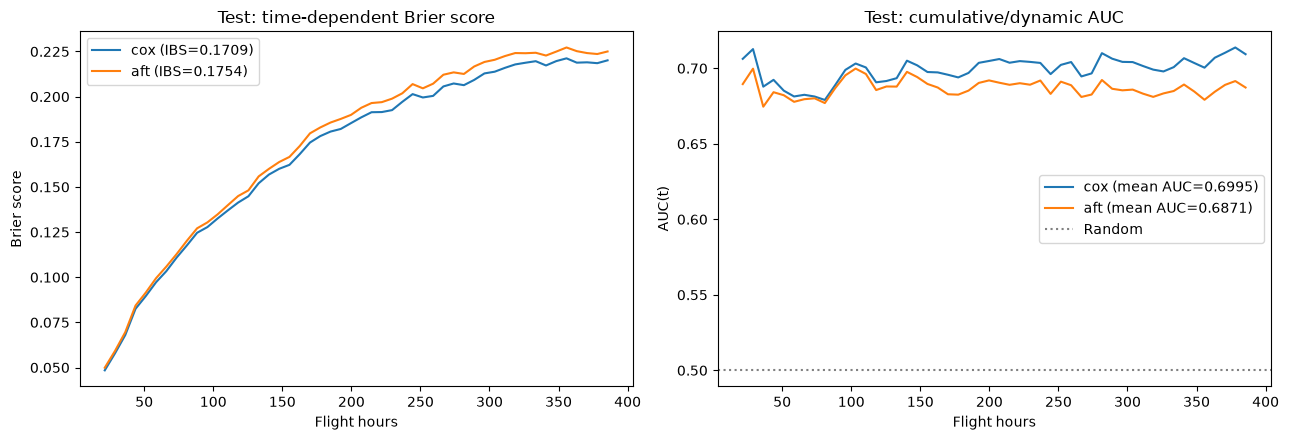

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

for name in models:
    r = results[(name, "test")]
    axes[0].plot(eval_times, r["brier"], label=f"{name} (IBS={r['ibs']:.4f})")
    axes[1].plot(eval_times, r["auc"], label=f"{name} (mean AUC={r['mean_auc']:.4f})")

axes[0].set(
    title="Test: time-dependent Brier score",
    xlabel="Flight hours",
    ylabel="Brier score",
)
axes[1].axhline(0.5, color="grey", linestyle=":", label="Random")
axes[1].set(
    title="Test: cumulative/dynamic AUC", xlabel="Flight hours", ylabel="AUC(t)"
)
for ax in axes:
    ax.legend()

plt.tight_layout()
plt.show()

### 5.3 Calibration by prediction decile

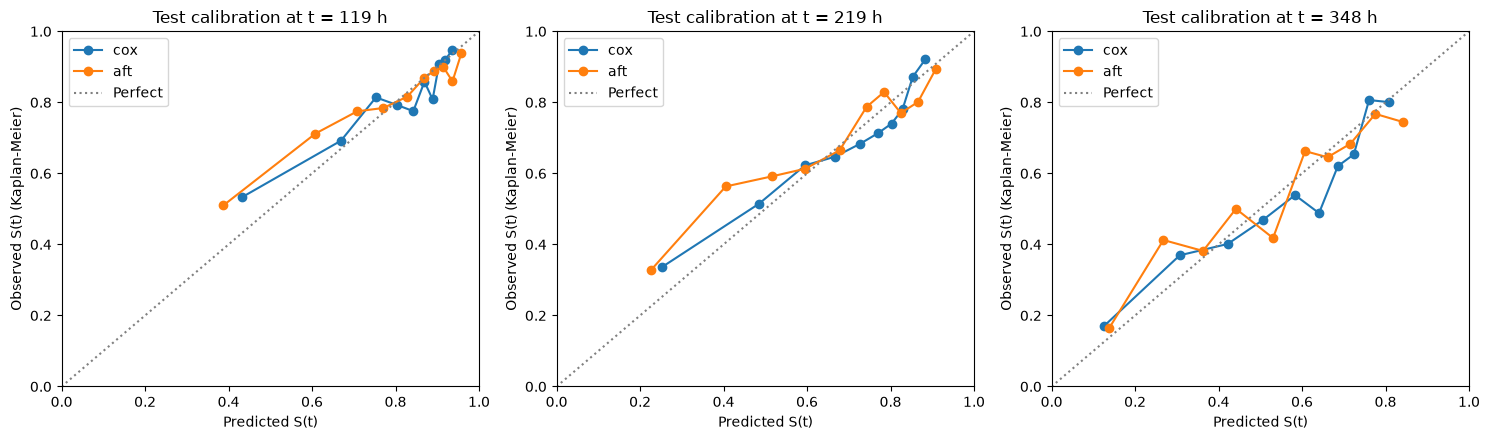

In [17]:
horizons = np.quantile(test["duration_h"], [0.25, 0.5, 0.75])
calibration = pd.concat(
    calibration_curve(model, test, h).assign(model=name, horizon=h)
    for name, model in models.items()
    for h in horizons
)
fig, axes = plt.subplots(1, len(horizons), figsize=(15, 4.5))

for ax, h in zip(axes, horizons):
    for name, cal in calibration[calibration["horizon"] == h].groupby("model", sort=False):
        ax.plot(cal["predicted"], cal["observed"], marker="o", label=name)
    ax.plot([0, 1], [0, 1], color="grey", linestyle=":", label="Perfect")
    ax.set(
        title=f"Test calibration at t = {h:.0f} h",
        xlabel="Predicted S(t)",
        ylabel="Observed S(t) (Kaplan-Meier)",
        xlim=(0, 1),
        ylim=(0, 1),
    )
    ax.legend()

plt.tight_layout()
plt.show()

### 5.4 Cox vs AFT: paired bootstrap

In [18]:
# Paired bootstrap on test: both models scored on the same resampled rows
boot_summary, boot_samples = bootstrap_compare(
    models, test, test, eval_times, n_boot=1000, seed=42
)
boot_summary.round(4)

,model_a,model_b,metric,value_a,value_b,diff,ci_low,ci_high,p_value,better,significant
0,cox,aft,c_index,0.6717,0.6658,0.0060,-0.0050,0.0168,0.266,cox,False
1,cox,aft,c_index_ipcw,0.6648,0.6583,0.0064,-0.0037,0.0168,0.238,cox,False
2,cox,aft,mean_auc,0.6995,0.6871,0.0124,-0.0020,0.0268,0.080,cox,False
3,cox,aft,ibs,0.1709,0.1754,-0.0045,-0.0084,-0.0008,0.018,cox,True


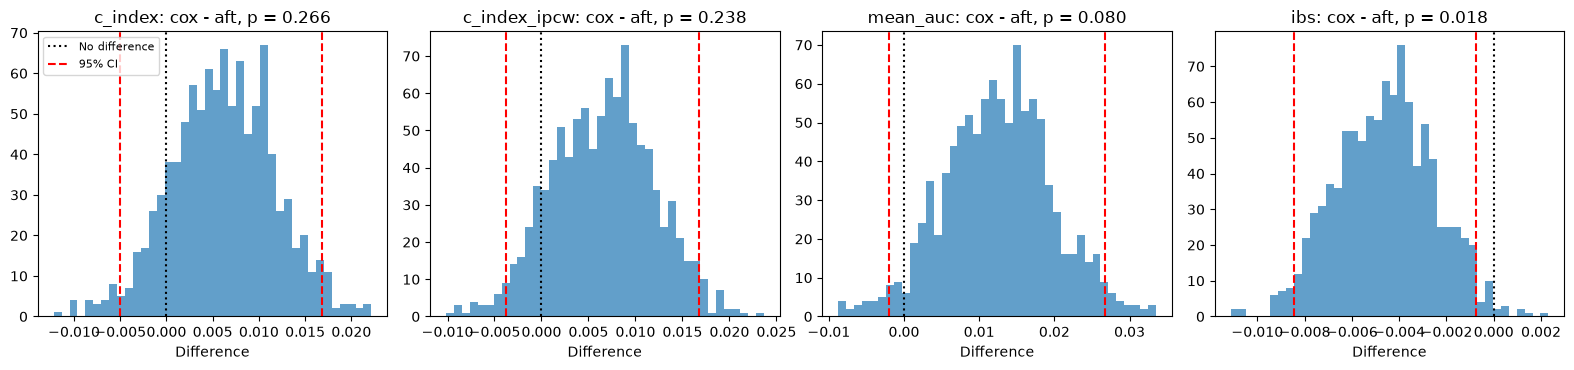

In [19]:
summary = boot_summary.set_index(["model_a", "model_b", "metric"])
a, b = "cox", "aft"

fig, axes = plt.subplots(1, len(SCALAR_METRICS), figsize=(16, 3.8))
for ax, metric in zip(axes, SCALAR_METRICS):
    row = summary.loc[(a, b, metric)]
    ax.hist(boot_samples[(a, metric)] - boot_samples[(b, metric)], bins=40, alpha=0.7)
    ax.axvline(0, color="black", linestyle=":", label="No difference")
    ax.axvline(row["ci_low"], color="red", linestyle="--", label="95% CI")
    ax.axvline(row["ci_high"], color="red", linestyle="--")
    ax.set(title=f"{metric}: {a} - {b}, p = {row['p_value']:.3f}", xlabel="Difference")
axes[0].legend(fontsize=8)

plt.tight_layout()
plt.show()

## 6. Risk factors (SHAP)

### 6.1 Feature importance

In [20]:
# SHAP of the risk score on test: positive values push towards earlier failure.
# Cox is in log-HR units and AFT in log-time units, so compare shares, not raw values.
shap_values = {name: model.explain(test) for name, model in models.items()}

shap_importance = pd.DataFrame(
    {name: np.abs(e.values).mean(axis=0) for name, e in shap_values.items()},
    index=FEATURES,
).sort_values(best_name, ascending=False)
shap_share = shap_importance / shap_importance.sum()

pd.concat({"mean |SHAP|": shap_importance, "share": shap_share}, axis=1).round(4)

mean |SHAP|           share        
                                cox     aft     cox     aft
hard_landings_per_100h       0.0778  1.8845  0.0529  0.5706
mean_temp_c                  0.3147  0.2801  0.2138  0.0848
avg_humidity_pct             0.1562  0.1886  0.1061  0.0571
firmware_major               0.1375  0.1484  0.0934  0.0449
environment                  0.1214  0.1408  0.0825  0.0426
initial_battery_cycles       0.1503  0.1271  0.1021  0.0385
avg_wind_ms                  0.0921  0.0972  0.0625  0.0294
operator_experience_yrs      0.0949  0.0864  0.0645  0.0262
payload_ratio                0.0739  0.0674  0.0502  0.0204
mean_vibration_g             0.0691  0.0509  0.0469  0.0154
daily_utilization_h          0.0273  0.0439  0.0185  0.0133
avg_payload_kg               0.0429  0.0430  0.0292  0.0130
maintenance_interval_h       0.0465  0.0426  0.0316  0.0129
avg_flight_min               0.0278  0.0421  0.0189  0.0127
is_refurbished               0.0230  0.0367  0.0156  0.0111
model                        0.0167  0.0229  0.0113  0.0069

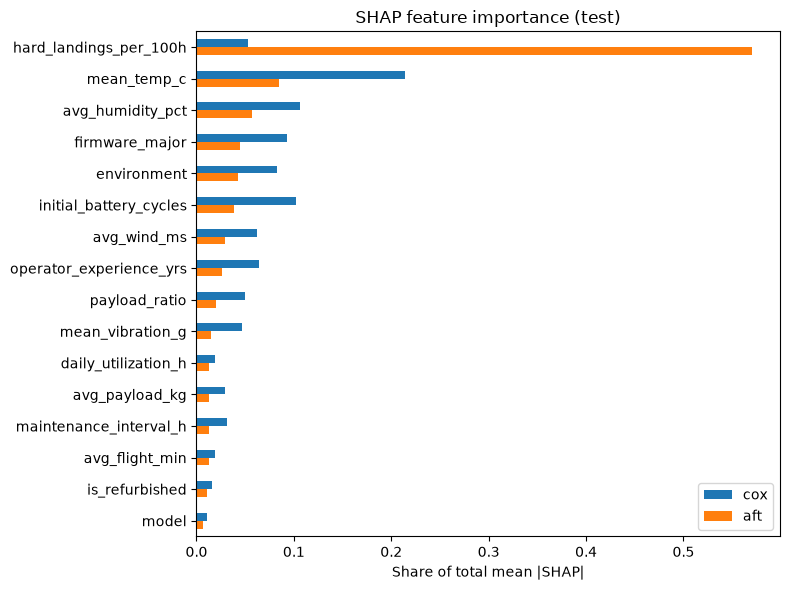

In [21]:
ax = shap_share.plot.barh(figsize=(8, 6))
ax.invert_yaxis()
ax.set(title="SHAP feature importance (test)", xlabel="Share of total mean |SHAP|")
plt.tight_layout()
plt.show()

### 6.2 Direction and shape of the effects

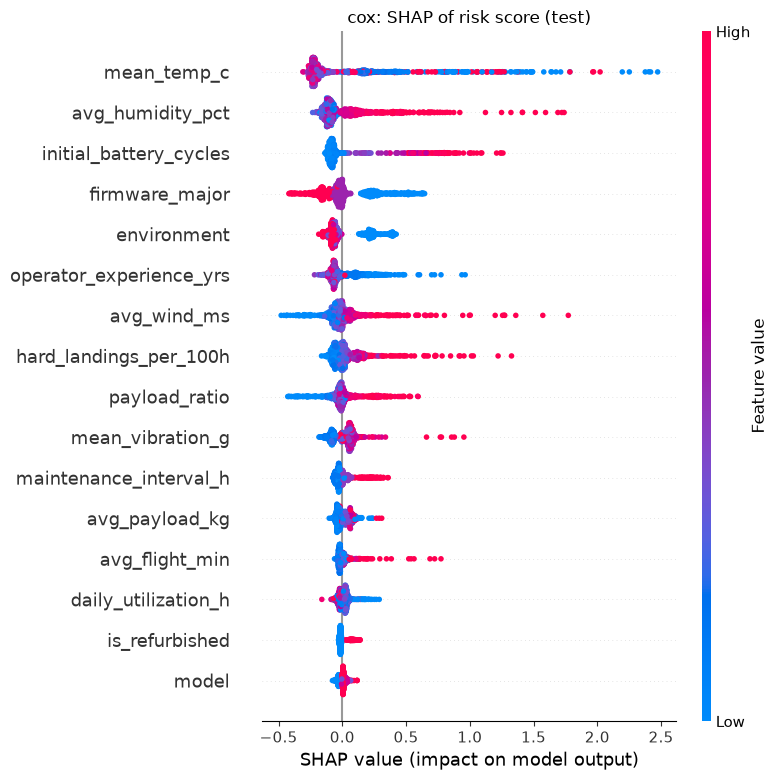

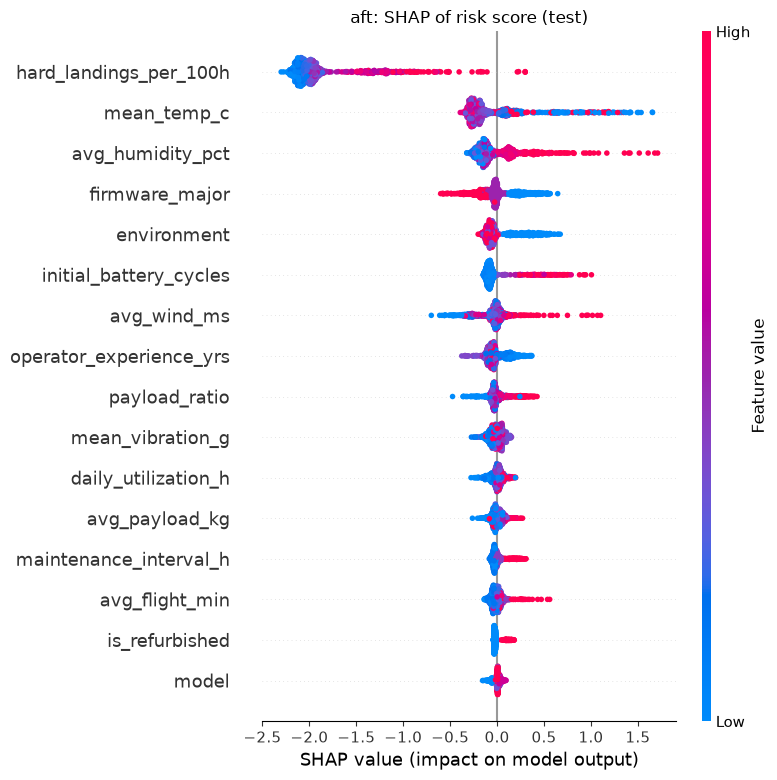

In [22]:
for name, explanation in shap_values.items():
    shap.plots.beeswarm(explanation, max_display=len(FEATURES), show=False)
    plt.title(f"{name}: SHAP of risk score (test)")
    plt.tight_layout()
    plt.show()

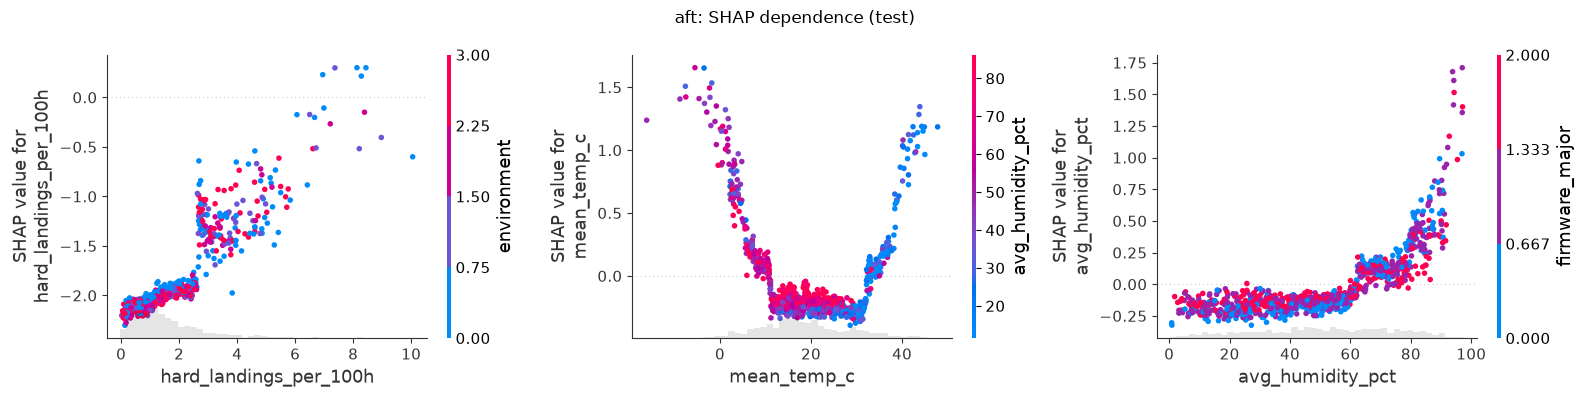

In [23]:
# Dependence plots for the best model's top features (categoricals shown as codes)
top_features = shap_importance.index[:3]
fig, axes = plt.subplots(1, len(top_features), figsize=(16, 4))
for ax, feature in zip(axes, top_features):
    shap.plots.scatter(
        shap_values[best_name][:, feature],
        color=shap_values[best_name],
        ax=ax,
        show=False,
    )
fig.suptitle(f"{best_name}: SHAP dependence (test)")
plt.tight_layout()
plt.show()

## 7. Remaining useful life

### 7.1 Conditional survival S(a + u) / S(a)

Left: fleet level at four ages, Kaplan-Meier vs the best model. Right: one drone at the same ages. The table is the probability of failing within the next 100 h.

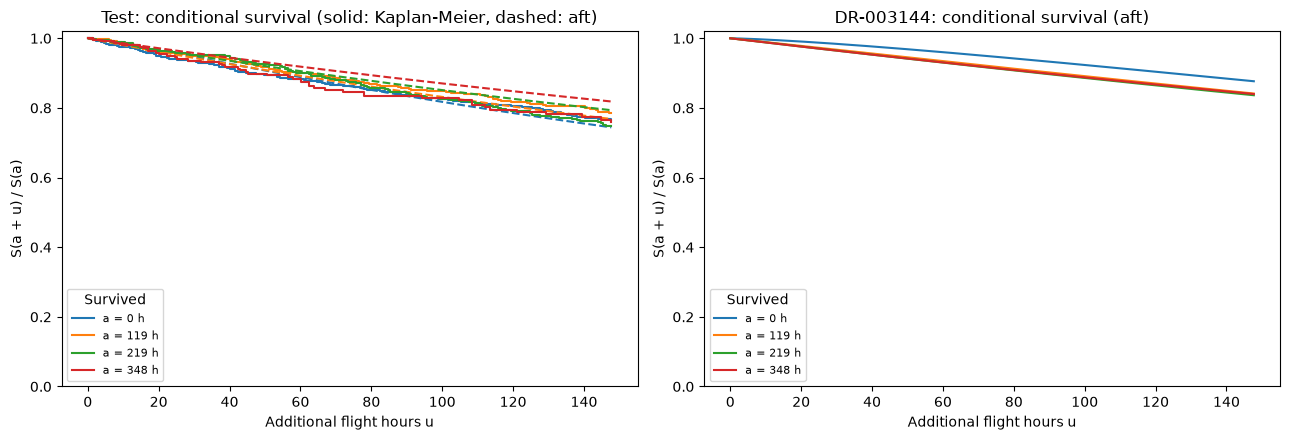

,age_h,observed P(fail in 100 h),aft P(fail in 100 h)
0,0.0,0.175,0.183
1,119.0,0.152,0.168
2,219.0,0.175,0.149
3,348.0,0.171,0.130


In [24]:
# Conditional survival S(a + u | T > a) = S(a + u) / S(a) = exp(-integral of h over
# [a, a + u]): the outlook of a drone that has already flown a hours. A flat hazard
# gives the same curve at every age; a rising one makes older drones' curves fall faster.
# Group level: observed is Kaplan-Meier S(a + u) / S(a); predicted is
# sum S_i(a + u) / sum S_i(a) (drones that failed before a drop out).
cond_ages = np.r_[0.0, np.quantile(test["duration_h"], [0.25, 0.5, 0.75])].round()
cond_grid = np.linspace(0, np.quantile(test["duration_h"], 0.9) - cond_ages[-1], 200)


def km_survival(times: np.ndarray) -> np.ndarray:
    """Test Kaplan-Meier at ``times`` (step function, 1 before the first event)."""
    i = np.searchsorted(km_time, times, side="right") - 1
    return np.where(i >= 0, km_surv[np.maximum(i, 0)], 1.0)


fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

ax = axes[0]
test_surv = best_model.survival(test, np.r_[cond_ages, np.add.outer(cond_ages, cond_grid).ravel()])
s_age = test_surv[:, : len(cond_ages)].sum(axis=0)
s_ahead = test_surv[:, len(cond_ages) :].sum(axis=0).reshape(len(cond_ages), -1)
window_rows = []
for k, a in enumerate(cond_ages):
    observed = km_survival(a + cond_grid) / km_survival(a)
    predicted = s_ahead[k] / s_age[k]
    ax.step(cond_grid, observed, where="post", color=f"C{k}", label=f"a = {a:.0f} h")
    ax.plot(cond_grid, predicted, color=f"C{k}", linestyle="--")
    window_rows.append(
        {
            "age_h": a,
            f"observed P(fail in {RUL_WINDOW} h)": 1
            - km_survival(a + RUL_WINDOW) / km_survival(a),
            f"{best_name} P(fail in {RUL_WINDOW} h)": 1
            - np.interp(RUL_WINDOW, cond_grid, predicted),
        }
    )
ax.set(
    title=f"Test: conditional survival (solid: Kaplan-Meier, dashed: {best_name})",
    xlabel="Additional flight hours u",
    ylabel="S(a + u) / S(a)",
    ylim=(0, 1.02),
)
ax.legend(title="Survived", fontsize=8)

ax = axes[1]
drone = test.iloc[[idx[0]]]
drone_curves = best_model.conditional_survival(
    pd.concat([drone] * len(cond_ages)), cond_ages, cond_grid
)
for k, (a, s) in enumerate(zip(cond_ages, drone_curves)):
    ax.plot(cond_grid, s, color=f"C{k}", label=f"a = {a:.0f} h")
ax.set(
    title=f"{drone['drone_id'].iloc[0]}: conditional survival ({best_name})",
    xlabel="Additional flight hours u",
    ylabel="S(a + u) / S(a)",
    ylim=(0, 1.02),
)
ax.legend(title="Survived", fontsize=8)

plt.tight_layout()
plt.show()

pd.DataFrame(window_rows).round(3)

### 7.2 Backtest at a landmark

Left: mean predicted conditional survival vs Kaplan-Meier for the test drones still flying at the landmark. Right: predicted vs observed probability of failing within the next 100 h by quintile of the prediction, the quantity behind the maintenance priority. Points below the diagonal mean the model overstates the risk. The dashed line is the best model before the recalibration of section 3 (drawn if it was applied); the bars are the 95% interval of the observed share.

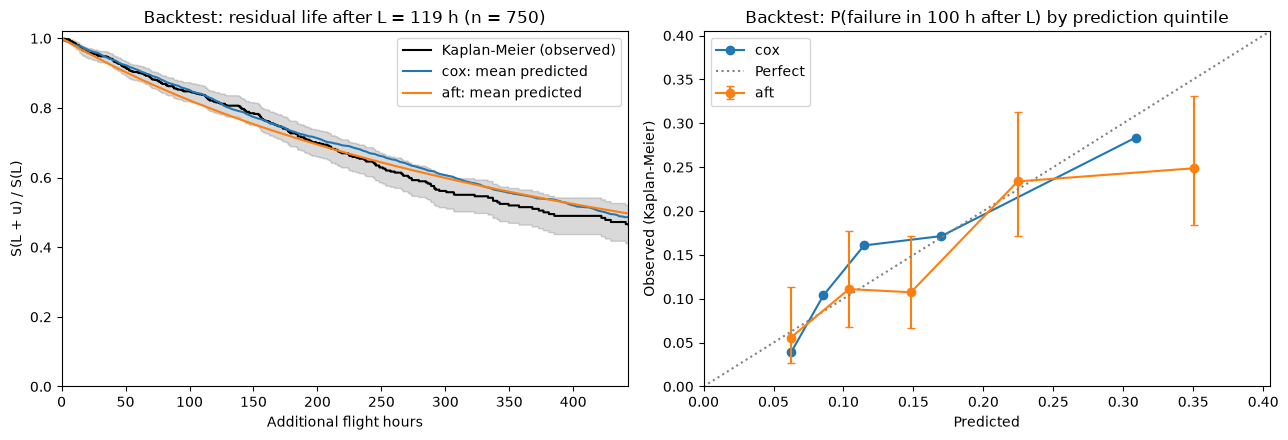

,source,quintile,n,predicted,observed,ci_low,ci_high
0,cox,1,150,0.062,0.039,0.016,0.091
1,cox,2,150,0.086,0.104,0.063,0.169
2,cox,3,150,0.115,0.161,0.109,0.234
3,cox,4,150,0.170,0.171,0.118,0.245
4,cox,5,150,0.309,0.284,0.215,0.368
5,aft,1,150,0.062,0.055,0.027,0.113
6,aft,2,150,0.104,0.111,0.068,0.178
7,aft,3,150,0.148,0.107,0.066,0.172
8,aft,4,150,0.225,0.234,0.172,0.313
9,aft,5,150,0.351,0.249,0.184,0.331


In [25]:
# Backtest: test drones still at risk at landmark L. Their observed residual life
# (Kaplan-Meier) should match the predicted conditional survival, for the whole group
# and inside each quintile of the predicted P(failure in RUL_WINDOW h).
landmark = np.quantile(test["duration_h"], 0.25)
at_risk = test[test["duration_h"] > landmark]
residual = at_risk["duration_h"] - landmark
at_risk_event = at_risk["event"].astype(bool)
at_risk_age = np.full(len(at_risk), landmark)

km_t, km_s, km_ci = kaplan_meier_estimator(at_risk_event, residual, conf_type="log-log")
u = np.linspace(0, residual.quantile(0.9), 200)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

ax = axes[0]
ax.step(km_t, km_s, where="post", color="black", label="Kaplan-Meier (observed)")
ax.fill_between(km_t, km_ci[0], km_ci[1], step="post", color="black", alpha=0.15)
for name, model in models.items():
    pred = model.conditional_survival(at_risk, at_risk_age, u)
    ax.plot(u, pred.mean(axis=0), label=f"{name}: mean predicted")
ax.set(
    title=f"Backtest: residual life after L = {landmark:.0f} h (n = {len(at_risk)})",
    xlabel="Additional flight hours",
    ylabel="S(L + u) / S(L)",
    xlim=(0, u[-1]),
    ylim=(0, 1.02),
)
ax.legend()

ax = axes[1]
# "raw": the best model without the recalibration, to show what it changes
backtest_models = dict(models)
if best_model.calibration is not None:
    backtest_models["raw"] = copy.copy(best_model)
    backtest_models["raw"].calibration = None
group_rows = []
for name, model in backtest_models.items():
    p_fail = 1 - model.conditional_survival(at_risk, at_risk_age, np.array([RUL_WINDOW]))[:, 0]
    quintile = pd.qcut(p_fail, 5, labels=False)
    for q in np.unique(quintile):
        in_group = quintile == q
        group_t, group_s, group_ci = kaplan_meier_estimator(
            at_risk_event[in_group], residual[in_group], conf_type="log-log"
        )
        at_window = np.searchsorted(group_t, RUL_WINDOW, side="right") - 1
        group_rows.append(
            {
                "source": name,
                "quintile": q + 1,
                "n": int(in_group.sum()),
                "predicted": p_fail[in_group].mean(),
                "observed": 1 - group_s[at_window],
                "ci_low": 1 - group_ci[1][at_window],
                "ci_high": 1 - group_ci[0][at_window],
            }
        )
backtest_groups = pd.DataFrame(group_rows)
for name, rows in backtest_groups.groupby("source", sort=False):
    if name == "raw":
        ax.plot(
            rows["predicted"],
            rows["observed"],
            marker="o",
            color="grey",
            linestyle="--",
            label=f"{best_name} before recalibration",
        )
    elif name == best_name:
        ax.errorbar(
            rows["predicted"],
            rows["observed"],
            yerr=[rows["observed"] - rows["ci_low"], rows["ci_high"] - rows["observed"]],
            marker="o",
            capsize=3,
            label=name,
        )
    else:
        ax.plot(rows["predicted"], rows["observed"], marker="o", label=name)
top = 1.1 * backtest_groups[["predicted", "ci_high"]].to_numpy().max()
ax.plot([0, top], [0, top], color="grey", linestyle=":", label="Perfect")
ax.set(
    title=f"Backtest: P(failure in {RUL_WINDOW} h after L) by prediction quintile",
    xlabel="Predicted",
    ylabel="Observed (Kaplan-Meier)",
    xlim=(0, top),
    ylim=(0, top),
)
ax.legend()

plt.tight_layout()
plt.show()

backtest_groups.round(3)

## 8. Production model

Sections 3-7 describe the evaluation models: tuned on train, early-stopped on validation, reported on test. New drones are scored by **production** models: the same parameters and the number of boosting rounds early stopping selected, refitted on train + validation, so the newest drones before the test split are not wasted. The category vocabulary, the Breslow baseline, the recalibration (out-of-fold on train + validation) and the feature ranges are recomputed. The number of rounds is not rescaled for the larger sample.

### 8.1 Refit and release gate

Every production model is compared with its evaluation model on test (`trainer.release.release_gate`): Uno's C-index and IBS may be worse by at most a tolerance; the mean decile calibration error over the three horizons of section 5.3 and the landmark backtest of section 7.2 (risk quintiles inside the 95% interval) have absolute limits; predictions must survive save and load, be finite, and the recalibration must converge. `reference` is the evaluation model's value. A model that fails any check is not released. If the model selected on validation fails and the other one passes, the other one makes the forecasts.

Test is used twice, for the report in section 5 and for this check, so the check is slightly optimistic; the limits are defaults of `GateConfig`, not tuned to this run.

In [26]:
train_val = pd.concat([train, val])

production = build_production(
    models,
    best_name,
    train_val,
    test,
    eval_times=eval_times,
    horizons=horizons,
    landmark=landmark,
    evaluation_metrics=metrics,
    evaluation_calibration=calibration,
    models_dir=Path(MODELS_DIR),
    config=GateConfig(),
    window=RUL_WINDOW,
)
gate = production.gate
forecast_name = production.forecast_name
forecast_model = production.models[forecast_name]

print(
    f"Selected on validation: {best_name}; passed the gate: "
    f"{[kind for kind, result in gate['kinds'].items() if result['passed']]}; "
    f"forecasts: production {forecast_name}"
)
pd.concat(
    {
        kind: pd.DataFrame(result["checks"]).set_index("name")
        for kind, result in gate["kinds"].items()
    },
    names=["model", "check"],
).round(4)

Selected on validation: aft; passed the gate: ['cox']; forecasts: production cox


value  reference  threshold  passed
model check                                                  
cox   c_index_ipcw       0.6661     0.6648     0.6548    True
      ibs                0.1691     0.1709     0.1759    True
      calibration_error  0.0413     0.0450     0.0500    True
      backtest_groups    5.0000        NaN     4.0000    True
      roundtrip          0.0000        NaN     0.0000    True
      finite             1.0000        NaN     1.0000    True
      recalibration      1.0000        NaN     1.0000    True
aft   c_index_ipcw       0.6569     0.6583     0.6483    True
      ibs                0.1753     0.1754     0.1804    True
      calibration_error  0.0559     0.0532     0.0500   False
      backtest_groups    5.0000        NaN     4.0000    True
      roundtrip          0.0000        NaN     0.0000    True
      finite             1.0000        NaN     1.0000    True
      recalibration      1.0000        NaN     1.0000    True

### 8.2 Evaluation vs production on test

Metrics of both stages on the same test grid, then what was refitted: rows used, boosting rounds and the recalibration (a variance of 0 means it was not applied).

In [27]:
pd.concat(
    {"evaluation": metrics.xs("test", level="split"), "production": production.metrics},
    axis=1,
).round(4)

evaluation                               production               \
         c_index c_index_ipcw mean_auc     ibs    c_index c_index_ipcw   
model                                                                    
cox       0.6717       0.6648   0.6995  0.1709     0.6724       0.6661   
aft       0.6658       0.6583   0.6871  0.1754     0.6645       0.6569   

                        
      mean_auc     ibs  
model                   
cox     0.6995  0.1691  
aft     0.6860  0.1753

In [28]:
pd.DataFrame(
    {
        name: {
            "rows": production.n_train,
            "rounds": production.rounds[name],
            "frailty_variance": (model.calibration or {}).get("frailty_variance", 0.0),
            "scale": (model.calibration or {}).get("scale", 1.0),
            "recalibration applied": model.calibration is not None,
        }
        for name, model in production.models.items()
    }
).T

,rows,rounds,frailty_variance,scale,recalibration applied
cox,3999,118,0.267823,1.045312,True
aft,3999,346,0.0,1.0,False


### 8.3 Drones in service

Forecast for the test drones in service at the data cut-off (section 2) by the production model; these drones are out of sample for it. The horizon keeps age + horizon inside the Cox baseline support, which now ends at the last failure in train + validation. The far end of that support rests on few drones (printed below), so long-horizon figures for the oldest drones are noisy.

In [29]:
# Drones in service at the data cut-off; current age = duration_h
active = test[test["in_service"]]
horizon = production.horizon
rul = production.rul
print(f"Model: production {forecast_name}, horizon: {horizon:.0f} h, drones in service: {len(rul)}")

last_event = train_val.loc[train_val["event"] == 1, "duration_h"].max()
support = np.array([0.5, 0.75, 1.0]) * last_event
still_flying = [int((train_val["duration_h"] >= t).sum()) for t in support]
print(f"Train + validation drones still at risk at {support.round().tolist()} h: {still_flying}")
rul.sort_values("p_fail_window", ascending=False).head(10).round(3)

Model: production cox, horizon: 1111 h, drones in service: 500
Train + validation drones still at risk at [1174.0, 1761.0, 2348.0] h: [128, 20, 4]


,drone_id,age_h,rul_q10,rul_median,rmrl,p_fail_window
751,DR-000751,59.10,6.666,38.885,66.288,0.795
2709,DR-002709,336.16,17.776,95.546,159.926,0.518
3616,DR-003616,145.55,15.554,99.990,155.655,0.508
3580,DR-003580,463.74,18.887,99.990,172.230,0.506
3057,DR-003057,193.50,17.776,107.767,178.111,0.470
336,DR-000336,51.00,19.998,119.988,177.589,0.441
3764,DR-003764,83.04,15.554,126.654,188.076,0.426
4442,DR-004442,250.19,17.776,124.432,191.138,0.425
1176,DR-001176,200.64,23.331,142.208,214.856,0.410
3430,DR-003430,186.20,22.220,139.986,218.719,0.400


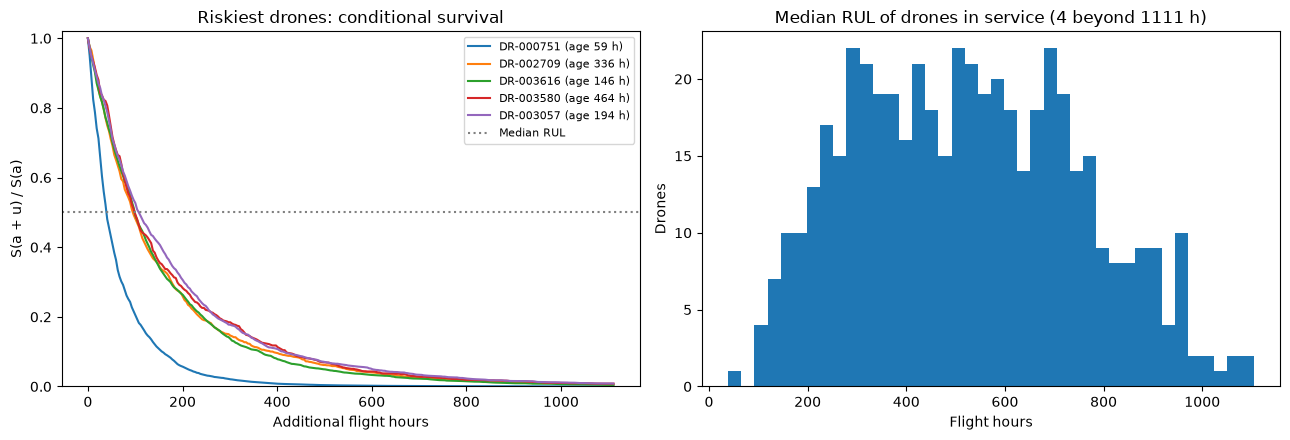

In [30]:
rul_grid = np.linspace(0, horizon, 300)
riskiest = rul.nlargest(5, "p_fail_window").index
rul_curves = forecast_model.conditional_survival(
    active.loc[riskiest], active.loc[riskiest, "duration_h"], rul_grid
)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

ax = axes[0]
for k, (i, s) in enumerate(zip(riskiest, rul_curves)):
    label = f"{active.at[i, 'drone_id']} (age {active.at[i, 'duration_h']:.0f} h)"
    ax.plot(rul_grid, s, color=f"C{k}", label=label)
ax.axhline(0.5, color="grey", linestyle=":", label="Median RUL")
ax.set(
    title="Riskiest drones: conditional survival",
    xlabel="Additional flight hours",
    ylabel="S(a + u) / S(a)",
    ylim=(0, 1.02),
)
ax.legend(fontsize=8)

ax = axes[1]
finite = np.isfinite(rul["rul_median"])
ax.hist(rul.loc[finite, "rul_median"], bins=40)
ax.set(
    title=f"Median RUL of drones in service ({(~finite).sum()} beyond {horizon:.0f} h)",
    xlabel="Flight hours",
    ylabel="Drones",
)

plt.tight_layout()
plt.show()

The same drones by the evaluation model selected on validation, i.e. the queue before the production stage: rows are its maintenance priority, columns the production model's.

In [31]:
last_train_event = train.loc[train["event"] == 1, "duration_h"].max()
evaluation_rul = remaining_life(
    best_model,
    active,
    horizon=np.floor(last_train_event - active["duration_h"].max()),
    window=RUL_WINDOW,
)


def priority_of(p_fail: pd.Series) -> pd.Series:
    return pd.cut(
        p_fail,
        [-np.inf, PRIORITY_MEDIUM, PRIORITY_HIGH, np.inf],
        labels=["Low", "Medium", "High"],
        right=False,
    )


print(
    f"Expected failures in {RUL_WINDOW} h: evaluation {best_name} "
    f"{evaluation_rul['p_fail_window'].sum():.1f}, "
    f"production {forecast_name} {rul['p_fail_window'].sum():.1f}; "
    "rank correlation of the two forecasts: "
    f"{evaluation_rul['p_fail_window'].corr(rul['p_fail_window'], method='spearman'):.3f}"
)
pd.crosstab(
    priority_of(evaluation_rul["p_fail_window"]).rename(f"evaluation {best_name}"),
    priority_of(rul["p_fail_window"]).rename(f"production {forecast_name}"),
    dropna=False,
)

Expected failures in 100 h: evaluation aft 70.3, production cox 74.3; rank correlation of the two forecasts: 0.902


production cox,Low,Medium,High
evaluation aft,,,
Low,375,31,0
Medium,20,69,3
High,0,1,1


## 9. Artifacts for the dashboards

`trainer.artifacts.write_artifacts` is the single writer shared with the training studio. Quality tables describe the evaluation models; the fleet forecast, risk groups and `shap_production` come from the production model. The model card records the data fingerprint, parameters, library versions, metrics and the gate result.

In [32]:
split = {
    "t_val": str(t_val.date()),
    "t_test": str(t_test.date()),
    "n_train": len(train),
    "n_val": len(val),
    "n_test": len(test),
}
card = model_card(
    frame=df,
    split=split,
    models=models,
    best_name=best_name,
    evaluation_metrics=metrics,
    production=production,
    train_val=train_val,
    settings={"n_trials": N_TRIALS, "n_boot": len(boot_samples), "seed": 42},
)
meta = write_artifacts(
    Path(ARTIFACTS_DIR),
    test=test,
    models=models,
    best_name=best_name,
    metrics=metrics,
    results=results,
    eval_times=eval_times,
    horizons=horizons,
    calibration=calibration,
    boot_summary=boot_summary,
    boot_samples=boot_samples,
    shap_values=shap_values,
    grid=grid,
    landmark=landmark,
    backtest_u=u,
    backtest_groups=backtest_groups,
    production=production,
    card=card,
    split=split,
    n_trials=N_TRIALS,
)

sorted(os.listdir(ARTIFACTS_DIR))

['backtest.parquet',
 'backtest_groups.parquet',
 'bootstrap_samples.parquet',
 'bootstrap_summary.parquet',
 'brier_auc.parquet',
 'calibration.parquet',
 'meta.json',
 'metrics.parquet',
 'model_card.json',
 'predictions.parquet',
 'shap_importance.parquet',
 'shap_production.parquet',
 'shap_values.parquet',
 'survival_mean.parquet']